# Part 2 | Model training and ensemble evaluation

This notebook forecasts next-day rainfall in millimetres. It compares single models, tree ensembles and a voting ensemble using the chronological splits prepared in Part 1.

The archive includes `rainfall_outputs/forecast_dataset.csv` and the saved model outputs. In Colab, you can upload `forecast_dataset.csv` to the Files panel directly. In Jupyter, leave it in `rainfall_outputs/` or place it beside the notebook. Run the cells from top to bottom. The saved displays show results from the combined notebook run.

### Load the forecast dataset and restore the date splits

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

OUT = Path('rainfall_outputs')
OUT.mkdir(exist_ok=True)

dataset = Path('forecast_dataset.csv')
if not dataset.exists():
    dataset = OUT / dataset.name

data = pd.read_csv(dataset, parse_dates=['date', 'target_date'], float_precision='round_trip')

TARGET = 'rain_next_day_mm'
train = data.loc[data['split'].eq('train')].copy()
val = data.loc[data['split'].eq('validation')].copy()
test = data.loc[data['split'].eq('test')].copy()

assert len(train) and len(val) and len(test)
assert train.target_date.max() < val.target_date.min()
assert val.target_date.max() < test.target_date.min()
print(f'Train: {len(train):,} | Validation: {len(val):,} | Test: {len(test):,}')

### List the candidate features

In [ ]:
NUM = ['latitude', 'longitude', 'elevation', 'rain_sum', 'rain_yesterday_mm',
       'rain_3day_mean_mm', 'season_sin', 'season_cos', 'wind_sin', 'wind_cos',
       'temperature_2m_mean', 'temperature_range', 'sunshine_duration',
       'wind_speed_10m_max', 'wind_gusts_10m_max', 'shortwave_radiation_sum',
       'et0_fao_evapotranspiration']
FEATURES = NUM + ['city_name']

## 3. Train single models and ensembles
After screening out IDs, redundant columns and fields unavailable at forecast time, each pipeline fits median imputation and selects 12 of 17 numerical candidates by univariate F-score. The F-score measures linear association with tomorrow's rain and may miss nonlinear interactions. The nominal city is retained as a separate one-hot encoded predictor, giving 13 selected inputs before encoding. Each fold and final refit learn their own selection. An all-candidate ablation on the validation year checks whether filtering helps histogram boosting. Standardization and one-hot encoding are also fitted inside the pipeline. Scaling matters for ridge and nearest neighbours; trees use the unscaled values. Random forest and Extra Trees average randomized trees to reduce variance; histogram gradient boosting adds trees that correct earlier errors. The voting ensemble averages the two strongest tree ensembles on validation RMSE. A persistence baseline uses today's rain; a seasonal baseline uses past city/month averages. All use the same dates and target.

### Import the model tools

In [ ]:
import joblib
import sklearn
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor, HistGradientBoostingRegressor, VotingRegressor
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.impute import SimpleImputer
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from threadpoolctl import threadpool_limits

# Keep CPU use predictable in Colab and on local machines.
cpu_limit = threadpool_limits(limits=2)
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

### Prepare inputs and select features

In [ ]:
def pipeline(estimator, scale=False, k=12):
    steps = [SimpleImputer(strategy='median', keep_empty_features=True),
             SelectKBest(f_regression, k=k)]
    if scale:
        steps.append(StandardScaler())
    numeric = make_pipeline(*steps)
    return make_pipeline(ColumnTransformer([
        ('numeric', numeric, NUM),
        ('city', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['city_name'])
    ]), estimator)

### Set up Ridge, KNN and Decision Tree

In [ ]:
single = {
    'Ridge': pipeline(Ridge(alpha=10), True),
    'KNN': pipeline(KNeighborsRegressor(n_neighbors=60, weights='distance', n_jobs=2), True),
    'Decision tree': pipeline(DecisionTreeRegressor(max_depth=10, min_samples_leaf=40, random_state=42)),
}

### Set up the three tree ensembles

In [ ]:
ensemble = {
    'Random forest': pipeline(RandomForestRegressor(n_estimators=75, max_depth=17, min_samples_leaf=12, max_features=.8, random_state=42, n_jobs=2)),
    'Extra trees': pipeline(ExtraTreesRegressor(n_estimators=75, max_depth=20, min_samples_leaf=10, max_features=.85, random_state=42, n_jobs=2)),
    'Histogram boosting': pipeline(HistGradientBoostingRegressor(max_iter=170, learning_rate=.07, max_leaf_nodes=31, l2_regularization=1, early_stopping=False, random_state=42)),
}

### Define the prediction and error calculations

In [ ]:
def predict(model, part):
    return np.maximum(model.predict(part[FEATURES]), 0)

def scores(part, prediction):
    y = part[TARGET]
    return {'RMSE_mm': np.sqrt(mean_squared_error(y, prediction)),
            'MAE_mm': mean_absolute_error(y, prediction), 'R2': r2_score(y, prediction)}

### Train six models and compare validation errors

In [ ]:
models = {**single, **ensemble}
validation = {}
for name, model in models.items():
    fitted = clone(model).fit(train[FEATURES], train[TARGET])
    validation[name] = scores(val, predict(fitted, val))
    print(name, round(validation[name]['RMSE_mm'], 3), 'validation RMSE')

    if name == 'Histogram boosting':
        numeric_fit = fitted[0].named_transformers_['numeric']
        selector = numeric_fit.named_steps['selectkbest']
        ranking = pd.DataFrame({'candidate': NUM, 'F_score': selector.scores_,
                                'selected': selector.get_support()}).sort_values('F_score', ascending=False)
        display(ranking.round(2))

Ridge 7.224 validation RMSE


KNN 7.367 validation RMSE


Decision tree 7.612 validation RMSE


Random forest 7.39 validation RMSE


Extra trees 7.336 validation RMSE


Histogram boosting 7.37 validation RMSE


,candidate,F_score,selected
3,rain_sum,31556.20,True
5,rain_3day_mean_mm,27967.85,True
16,et0_fao_evapotranspiration,22586.19,True
15,shortwave_radiation_sum,21698.06,True
12,sunshine_duration,20987.22,True
4,rain_yesterday_mm,12473.79,True
11,temperature_range,5548.50,True
10,temperature_2m_mean,3669.37,True
13,wind_speed_10m_max,2489.43,True
6,season_sin,2283.49,True


### Compare selected features against all candidates

In [ ]:
boost_all = pipeline(clone(ensemble['Histogram boosting'][-1]), k='all')
boost_all.fit(train[FEATURES], train[TARGET])
print('Boosting validation RMSE | selected inputs:',
      round(validation['Histogram boosting']['RMSE_mm'], 3),
      '| all candidates:', round(scores(val, predict(boost_all, val))['RMSE_mm'], 3))

Boosting validation RMSE | selected inputs: 7.37 | all candidates: 7.31


### Build the voting ensemble and choose the export model

In [ ]:
best_single = min(single, key=lambda name: validation[name]['RMSE_mm'])
voters = sorted(ensemble, key=lambda name: validation[name]['RMSE_mm'])[:2]
vote_name = 'Voting ensemble'
models[vote_name] = VotingRegressor([(f'model_{i}', clone(models[name])) for i, name in enumerate(voters)])
vote_fit = clone(models[vote_name]).fit(train[FEATURES], train[TARGET])
validation[vote_name] = scores(val, predict(vote_fit, val))
best_ensemble = min([*ensemble, vote_name], key=lambda name: validation[name]['RMSE_mm'])
selected = min(models, key=lambda name: validation[name]['RMSE_mm'])
print('Voters:', voters, '| Validation picks:', best_single, best_ensemble, '| Export:', selected)

Voters: ['Extra trees', 'Histogram boosting'] | Validation picks: Ridge Voting ensemble | Export: Ridge


### Expanding-window cross-validation
For the six model families, use three expanding training windows within the training era. Split whole target dates so all cities on the same day stay together. The later validation year still chooses the model and voting members, and the final test period stays separate.

### Make three expanding date windows

In [ ]:
dates = pd.Index(train.target_date.unique()).sort_values()
folds = []
for fit_dates, check_dates in TimeSeriesSplit(n_splits=3).split(dates):
    folds.append((np.flatnonzero(train.target_date.isin(dates[fit_dates])),
                  np.flatnonzero(train.target_date.isin(dates[check_dates]))))

### Check each model across the three windows

In [ ]:
def negative_rmse(model, X, y):
    return -np.sqrt(mean_squared_error(y, np.maximum(model.predict(X), 0)))

cv_rmse = {
    name: -cross_val_score(model, train[FEATURES], train[TARGET],
                           cv=folds, scoring=negative_rmse, error_score='raise')
    for name, model in {**single, **ensemble}.items()
}
cv_results = pd.DataFrame(cv_rmse, index=['Fold 1', 'Fold 2', 'Fold 3']).T
cv_results['Mean RMSE (mm)'] = cv_results.mean(axis=1)
display(cv_results.sort_values('Mean RMSE (mm)').round(3))

,Fold 1,Fold 2,Fold 3,Mean RMSE (mm)
Extra trees,9.271,8.352,9.038,8.887
KNN,9.316,8.420,9.144,8.960
Ridge,9.442,8.228,9.255,8.975
Random forest,9.334,8.560,9.122,9.005
Histogram boosting,9.511,8.799,9.133,9.148
Decision tree,9.741,9.080,9.363,9.395


## 4. Evaluate on dates held out from model selection
RMSE in mm emphasizes large misses, MAE in mm measures typical absolute error, and R² compares squared error with a constant test-mean reference. Lower RMSE and MAE are better; higher R² is better. The comparison below uses the best single model and best ensemble **chosen on validation**. A negative improvement means the ensemble did worse.

### Make two simple baseline forecasts

In [ ]:
dev = pd.concat([train, val])
seasonal = dev.groupby(['city_name', dev.target_date.dt.month])[TARGET].mean()
test_keys = pd.MultiIndex.from_arrays([test.city_name, test.target_date.dt.month])
preds = {
    'Persistence': test.rain_sum.fillna(dev.rain_sum.median()).to_numpy(),
    'City-month average': seasonal.reindex(test_keys).fillna(dev[TARGET].mean()).to_numpy()
}

### Refit models and predict the held-out dates

In [ ]:
for name, model in models.items():
    refit = clone(model).fit(dev[FEATURES], dev[TARGET])
    preds[name] = predict(refit, test)
    if name == selected:
        champion = refit

### Compare RMSE, MAE and R-squared

In [ ]:
test_metrics = {}
for name, prediction in preds.items():
    test_metrics[name] = scores(test, prediction)
test_scores = pd.DataFrame.from_dict(test_metrics, orient='index')
results = test_scores.join(pd.DataFrame(validation).T.add_prefix('Validation_'))
results.to_csv(OUT / 'model_metrics.csv', index_label='model')
display(results.sort_values('RMSE_mm').round(3))

,RMSE_mm,MAE_mm,R2,Validation_RMSE_mm,Validation_MAE_mm,Validation_R2
Extra trees,7.648,4.346,0.374,7.336,4.275,0.242
Voting ensemble,7.650,4.346,0.374,7.311,4.267,0.247
Random forest,7.661,4.366,0.372,7.390,4.342,0.231
Histogram boosting,7.724,4.378,0.362,7.370,4.289,0.235
KNN,7.730,4.356,0.361,7.367,4.291,0.236
Ridge,7.749,4.417,0.358,7.224,4.356,0.265
Decision tree,7.938,4.488,0.326,7.612,4.437,0.184
City-month average,8.719,5.187,0.187,NaN,NaN,NaN
Persistence,9.073,4.837,0.119,NaN,NaN,NaN


### Measure the ensemble gain and heavy-rain errors

In [ ]:
a, b = test_scores.loc[[best_single, best_ensemble], 'RMSE_mm']
print(f'{best_single}: {a:.3f} mm vs {best_ensemble}: {b:.3f} mm.')
print(f'Ensemble relative RMSE reduction: {100 * (a-b)/a:+.2f}%')
threshold = train[TARGET].quantile(.95)
heavy = test[TARGET].ge(threshold)
print(f'Heavy-rain check: training 95th percentile = {threshold:.2f} mm; test days = {heavy.sum()}')
display(pd.Series({n: mean_absolute_error(test.loc[heavy, TARGET], p[heavy])
                   for n, p in preds.items()}, name='Heavy-day MAE (mm)').round(2))

Ridge: 7.749 mm vs Voting ensemble: 7.650 mm.
Ensemble relative RMSE reduction: +1.27%
Heavy-rain check: training 95th percentile = 21.60 mm; test days = 1078


Persistence           16.98
City-month average    24.38
Ridge                 19.80
KNN                   19.14
Decision tree         19.53
Random forest         18.92
Extra trees           19.21
Histogram boosting    19.10
Voting ensemble       19.12
Name: Heavy-day MAE (mm), dtype: float64

### Save predictions and verify the trained model

In [ ]:
test[['target_date', 'city_name', TARGET]].assign(**preds).to_csv(
    OUT / 'test_predictions.csv', index=False)
joblib.dump({'model': champion, 'features': FEATURES, 'model_name': selected,
             'sklearn_version': sklearn.__version__, 'forecast_horizon_days': 1},
            OUT / 'rainfall_model.joblib', compress=3)
# Record which raw features the exported pipeline actually uses.
members = champion.estimators_ if selected == vote_name else [champion]
selected_by_member = []
for member in members:
    mask = member[0].named_transformers_['numeric'].named_steps['selectkbest'].get_support()
    selected_by_member.append(list(np.array(NUM)[mask]) + ['city_name'])
print('Selected features in exported model:', selected_by_member)
loaded = joblib.load(OUT / 'rainfall_model.joblib')
np.testing.assert_allclose(predict(loaded['model'], test.head()), preds[selected][:5])

Selected features in exported model: [[np.str_('latitude'), np.str_('rain_sum'), np.str_('rain_yesterday_mm'), np.str_('rain_3day_mean_mm'), np.str_('season_sin'), np.str_('temperature_2m_mean'), np.str_('temperature_range'), np.str_('sunshine_duration'), np.str_('wind_speed_10m_max'), np.str_('wind_gusts_10m_max'), np.str_('shortwave_radiation_sum'), np.str_('et0_fao_evapotranspiration'), 'city_name']]


### Plot model errors and observed versus predicted rainfall

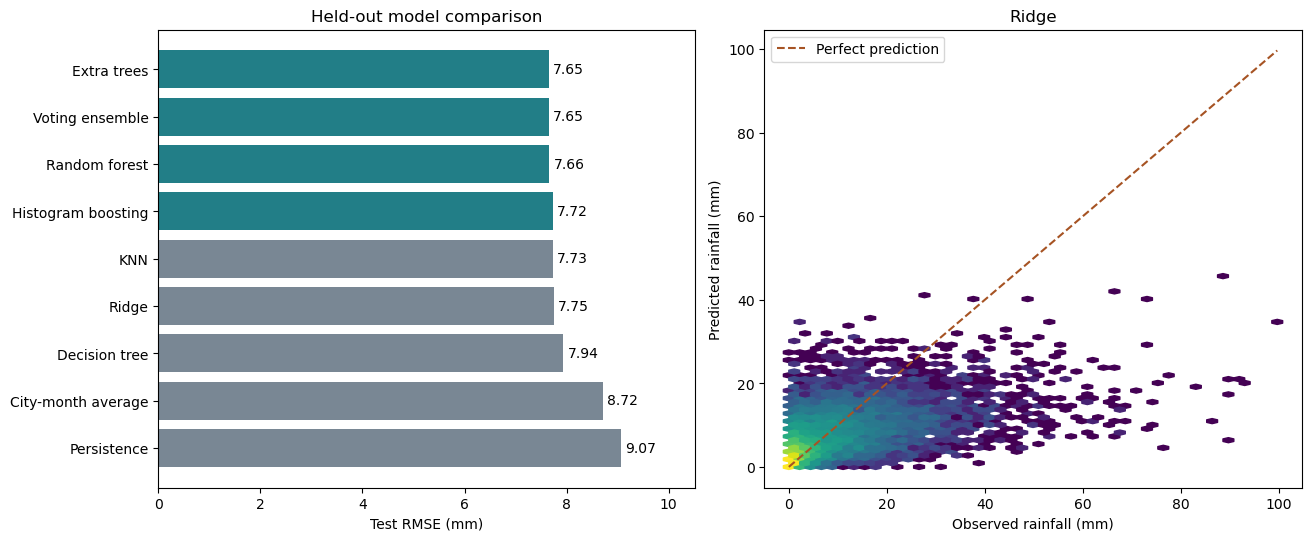

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.3), layout='constrained')
ordered = results['RMSE_mm'].sort_values(ascending=False)
axes[0].barh(ordered.index, ordered, color=['#227e87' if name in ensemble or name == vote_name
                                            else '#798794' for name in ordered.index])
axes[0].set(xlabel='Test RMSE (mm)', title='Held-out model comparison')
axes[0].bar_label(axes[0].containers[0], fmt='%.2f', padding=3)
axes[0].set_xlim(0, ordered.max() * 1.16)

actual = test[TARGET].to_numpy()
prediction = preds[selected]
axes[1].hexbin(actual, prediction, gridsize=45, bins='log', mincnt=1, cmap='viridis')
upper = max(actual.max(), prediction.max())
axes[1].plot([0, upper], [0, upper], '--', color='#a65323', label='Perfect prediction')
axes[1].set(xlabel='Observed rainfall (mm)', ylabel='Predicted rainfall (mm)', title=selected)
axes[1].legend()
fig.savefig(OUT / 'test_rmse.png', dpi=150)
plt.show()

### Plot average error for each city

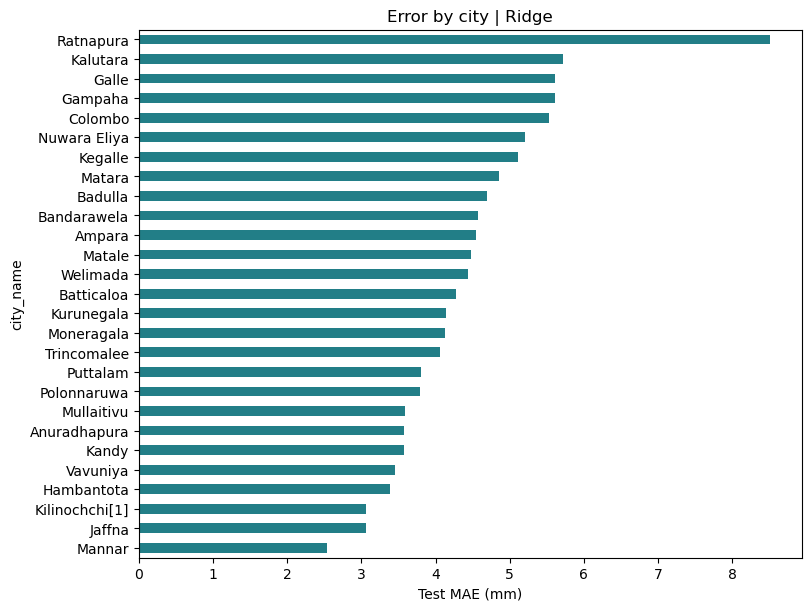

In [ ]:
residuals = test[['target_date', 'city_name', TARGET]].assign(error_mm=prediction - actual)
city_mae = residuals.groupby('city_name').error_mm.apply(lambda errors: errors.abs().mean())
fig, ax = plt.subplots(figsize=(8, 6), layout='constrained')
city_mae.sort_values().plot.barh(ax=ax, color='#227e87')
ax.set(xlabel='Test MAE (mm)', title=f'Error by city | {selected}')
plt.show()

### Discussion and website handoff

**Results from the supplied CSVs.** The 2022 validation year favored Ridge (7.224 mm RMSE) and chose the Extra Trees + Histogram Boosting vote as the best ensemble (7.311 mm). On the held-out dates, the vote reduced RMSE from 7.749 to 7.650 mm versus Ridge (1.27%) and beat the city-month average (8.719 mm) and persistence (9.073 mm). Extra Trees narrowly led the test RMSE at 7.648 mm. The vote had the lowest overall test MAE at 4.3460 mm. Ridge is exported according to the validation decision.

**Where the gains stopped.** On the 1,078 test location-days with at least 21.6 mm of observed rain, the voting model's MAE was 19.12 mm versus 16.98 mm for persistence. For histogram boosting, filtering from 18 candidate inputs to 13 increased validation RMSE from 7.31 to 7.37 mm. The ablation is reported separately from the common selected-feature benchmark. The rainfall plot also shows that the exported Ridge model tends to underestimate the largest totals.

- **Ridge** is fast and interpretable but cannot learn nonlinear interactions without additional features. **KNN** captures local patterns but depends on scaling and becomes expensive at prediction time. **Decision tree** captures nonlinear rules but is sensitive to changes in the training sample.
- **Random forest** reduces tree variance but can smooth peaks. **Extra Trees** randomizes split thresholds further, which can reduce variance but add bias. **Histogram boosting** learns successive corrections efficiently but may miss rare extreme events. **Voting** can help if its members make different errors; correlated errors or a weak member can limit the gain.
- Compare the test RMSE against both baselines and check the heavy-day MAE before claiming an improvement. The model uses historical observations only. It has no next-day atmospheric forecasts and has not been validated as an operational warning system.
- The exported joblib file includes the fitted transformations and model. For a live forecast, supply one row with the exact feature names and units used above, built from the latest completed day, earlier rain observations, location metadata and tomorrow's calendar date. Pin the training scikit-learn version and load only a trusted model file. The website should show the forecast date and units (mm).